# Sesi 00: persiapan Colab dan eksplorasi data

**Durasi:** 60 sampai 75 menit, termasuk contoh format pilihan.

Sesi 00 berfokus pada eksplorasi data atau **EDA (Exploratory Data Analysis)**:
mengenali isi tabel, memeriksa kualitasnya, merangkum angka, dan membaca grafik.
Pemodelan regresi baru dimulai pada Sesi 01.

Jalankan setiap sel dari atas dengan **Shift + Enter**. Data dibaca atau diunduh
otomatis dari GitHub; peserta tidak perlu mengunggah CSV atau ZIP.

**Posisi dalam alur workshop:** baca data, periksa, ringkas, lalu gambarkan.
Tuliskan temuan dengan satuan dan periode yang jelas. Hubungan pada grafik
belum menjadi bukti sebab akibat.

## 1. Siapkan Colab dan pembaca data

`%pip install` menyiapkan pembaca Excel, SPSS, dan Parquet pada runtime.
Pandas mengolah tabel; matplotlib dan seaborn membuat grafik.
Sel instalasi dan gaya grafik cukup dijalankan sebagaimana disediakan.

In [1]:
%pip install -q "openpyxl==3.1.5" "pyreadstat==1.3.2" "pyarrow==19.0.0"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"
URL_FORMAT = URL_DATA + "contoh_format/"

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.titleweight": "bold"})
print("pandas siap. Jalankan sel pembacaan data berikutnya.")

pandas siap. Jalankan sel pembacaan data berikutnya.


## 2. Membaca data Indonesia dalam berbagai format

Data dari rekan peneliti dapat berbentuk Excel, SPSS, atau Stata. Pandas
mengubah tabel-tabel itu menjadi bentuk yang sama: **DataFrame**, yaitu tabel
dengan baris dan kolom. Pilih perintah baca sesuai jenis berkasnya.

Kita memakai **satu tabel makro Indonesia, 2000 sampai 2025**, dari World Bank.
Satu baris mewakili satu tahun. Semua contoh memuat **26 baris dan tujuh kolom**.
CSV sumber sudah ada di `data/idn_makro_tahunan.csv`; enam salinan format lain
dikumpulkan di `data/contoh_format/`. Angka dan nama kolom dipertahankan agar
perbandingannya mudah. SPSS dan Stata di sini adalah hasil konversi untuk latihan,
bukan berkas mikrodata survei asli.

| Jenis berkas | Akhiran | Perintah pandas |
|---|---|---|
| CSV, teks dengan pemisah koma | `.csv` | `pd.read_csv(...)` |
| Microsoft Excel | `.xlsx` | `pd.read_excel(...)` |
| Data SPSS | `.sav` | `pd.read_spss(...)` |
| Data Stata | `.dta` | `pd.read_stata(...)` |
| Teks dengan pemisah tab | `.tsv` | `pd.read_csv(..., sep="\t")` |
| Tabel JSON | `.json` | `pd.read_json(...)` |
| Tabel Parquet | `.parquet` | `pd.read_parquet(...)` |

Jalankan empat contoh pertama bersama pengajar. TSV, JSON, dan Parquet dapat
dipelajari setelahnya. Berkas dibaca atau diunduh otomatis; tidak perlu unggah ZIP.

Sumber: [World Bank Indonesia](https://data.worldbank.org/country/indonesia),
[pertumbuhan PDB](https://data.worldbank.org/indicator/NY.GDP.MKTP.KD.ZG?locations=ID),
dan [inflasi IHK](https://data.worldbank.org/indicator/FP.CPI.TOTL.ZG?locations=ID).
Salinan latihan mengikuti lisensi CC BY 4.0.

### A. CSV: pemisah koma

`pd` adalah nama singkat pandas. `read_csv` membaca berkas, sedangkan
`makro_csv` menyimpan tabel hasilnya. `head()` menampilkan lima baris pertama.
Baca dahulu arti kolom pada tabel **Kenali data** di bawah.

<!-- kamus_variabel:idn_makro_tahunan.csv -->

### Kenali data: Makroekonomi Indonesia tahunan

**Data:** `data/idn_makro_tahunan.csv`. **Satu baris:** satu tahun kalender untuk Indonesia.

| Variabel/kolom | Pengertian | Satuan atau kode |
|---|---|---|
| `negara` | Kode negara; IDN menunjukkan Indonesia. | Kode ISO negara |
| `tahun` | Tahun kalender pengamatan. | Tahun |
| `PDB_Growth` | Laju pertumbuhan tahunan PDB riil (Produk Domestik Bruto). | Persen per tahun; NY.GDP.MKTP.KD.ZG |
| `Inflasi` | Kenaikan tahunan indeks harga konsumen. | Persen per tahun; FP.CPI.TOTL.ZG |
| `Pengangguran` | Pengangguran sebagai bagian dari total angkatan kerja, estimasi model ILO. | Persen angkatan kerja; SL.UEM.TOTL.ZS |
| `Kurs_USD` | Kurs resmi rata-rata periode: mata uang lokal untuk memperoleh satu dolar AS. | Mata uang lokal per US$1; PA.NUS.FCRF |
| `Angkatan_Kerja` | Penduduk yang bekerja atau aktif mencari pekerjaan. | Orang; SL.TLF.TOTL.IN |

Kurs_USD untuk Indonesia bersatuan rupiah per US$1. Inflasi dan pertumbuhan adalah laju persen, bukan nilai level harga atau level PDB.

Sumber definisi: [rujukan data](https://databank.worldbank.org/source/world-development-indicators).


In [3]:
makro_csv = pd.read_csv(URL_DATA + "idn_makro_tahunan.csv")
makro_csv.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


`negara` berisi `IDN`, yaitu Indonesia. `tahun` berisi tahun kalender.
Angka pada kolom PDB, inflasi, dan pengangguran adalah persentase, sedangkan
kurs dinyatakan dalam rupiah per dolar AS. Data ini dipakai lagi pada kasus
Indonesia di Lab 06; pada tahap ini kita belajar membaca dan mengenali tabelnya.

### B. Excel: pilih lembar yang berisi data

Berkas ini memiliki lembar `data` dan `sumber`. `sheet_name="data"` memilih
lembar angka; lembar `sumber` berisi definisi dan asal data.

In [4]:
makro_excel = pd.read_excel(URL_FORMAT + "idn_makro_tahunan.xlsx", sheet_name="data")
makro_excel.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### C. SPSS: unduh, lalu baca berkas `.sav`

`read_spss` memerlukan berkas lokal. `urlretrieve` mengunduh salinannya ke
runtime notebook dengan nama yang kita tentukan. Baris berikutnya membaca
berkas tersebut menjadi tabel pandas. Sel instalasi sudah menyiapkan `pyreadstat`.
Tidak perlu membuka aplikasi SPSS.

In [5]:
from urllib.request import urlretrieve

urlretrieve(URL_FORMAT + "idn_makro_tahunan.sav", "idn_makro_tahunan.sav")
makro_spss = pd.read_spss("idn_makro_tahunan.sav")
makro_spss.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000.0,4.920068,3.688620,6.077,8421.775000,101308307.0
1,IDN,2001.0,3.643466,11.500116,6.082,10260.850000,102354432.0
2,IDN,2002.0,4.499475,11.900120,6.604,9311.191667,102498864.0
3,IDN,2003.0,4.780369,6.757313,6.657,8577.133333,103909546.0
4,IDN,2004.0,5.030874,6.064062,7.303,8938.850000,105759801.0


### D. Stata: baca berkas `.dta`

`read_stata` dapat langsung membaca alamat berkas. `.dta` menyimpan data;
berkas `.do` adalah script Stata, sehingga tidak dibaca sebagai tabel.

In [6]:
makro_stata = pd.read_stata(URL_FORMAT + "idn_makro_tahunan.dta")
makro_stata.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### E. TSV: teks dengan pemisah tab

CSV dan TSV sama-sama berupa teks. `sep="\t"` menjelaskan bahwa batas antarkolom
adalah tab. Untuk berkas berpemisah titik koma, gunakan `sep=";"`.

In [7]:
makro_tsv = pd.read_csv(URL_FORMAT + "idn_makro_tahunan.tsv", sep="\t")
makro_tsv.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### F. JSON: daftar catatan

JSON sering dipakai untuk pertukaran data melalui web. Pada contoh yang sudah
disiapkan ini, satu catatan mewakili satu tahun. `orient="records"` menyatakan
susunan tersebut. JSON dari situs lain dapat memiliki struktur bertingkat
yang perlu dirapikan terlebih dahulu.

In [8]:
makro_json = pd.read_json(URL_FORMAT + "idn_makro_tahunan.json", orient="records")
makro_json.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### G. Parquet: penyimpanan tabel per kolom

Parquet sering dipakai untuk menyimpan tabel dalam proyek analisis data.
Perintah bacanya tetap pendek; paket `pyarrow` sudah disiapkan pada sel instalasi.

In [9]:
makro_parquet = pd.read_parquet(URL_FORMAT + "idn_makro_tahunan.parquet")
makro_parquet.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


### Periksa hasil baca sebelum menganalisis

`shape` menampilkan pasangan jumlah baris dan kolom. Tujuh hasil baca berikut
seharusnya sama-sama `(26, 7)`. Bandingkan pula lima baris pertama di atas:
tahun, nama kolom, dan nilainya tetap sama meskipun format berkas berbeda.

In [10]:
print("CSV     :", makro_csv.shape)
print("Excel   :", makro_excel.shape)
print("SPSS    :", makro_spss.shape)
print("Stata   :", makro_stata.shape)
print("TSV     :", makro_tsv.shape)
print("JSON    :", makro_json.shape)
print("Parquet :", makro_parquet.shape)

CSV     : (26, 7)
Excel   : (26, 7)
SPSS    : (26, 7)
Stata   : (26, 7)
TSV     : (26, 7)
JSON    : (26, 7)
Parquet : (26, 7)


## 3. Periksa isi dan kualitas tabel

`shape` menampilkan jumlah baris dan kolom. `info()` menampilkan nama kolom,
tipe data, dan banyaknya nilai yang terisi. `negara` adalah teks, sedangkan
tahun dan indikator ekonomi pada contoh ini berupa angka.

In [11]:
print("Jumlah baris dan kolom:", makro_csv.shape)
makro_csv.info()

Jumlah baris dan kolom: (26, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   negara          26 non-null     object 
 1   tahun           26 non-null     int64  
 2   PDB_Growth      26 non-null     float64
 3   Inflasi         26 non-null     float64
 4   Pengangguran    26 non-null     float64
 5   Kurs_USD        26 non-null     float64
 6   Angkatan_Kerja  26 non-null     int64  
dtypes: float64(4), int64(2), object(1)
memory usage: 1.6+ KB


### Cari nilai kosong dan baris berulang

`isna()` memeriksa nilai kosong. `sum()` menghitungnya pada setiap kolom.
`duplicated()` memeriksa baris yang seluruh isinya sama dengan baris sebelumnya.
Nilai kosong berbeda dari angka nol; jangan langsung mengisinya dengan nol.

In [12]:
print("Nilai kosong per kolom:")
print(makro_csv.isna().sum())
print("Baris berulang:", makro_csv.duplicated().sum())

Nilai kosong per kolom:
negara            0
tahun             0
PDB_Growth        0
Inflasi           0
Pengangguran      0
Kurs_USD          0
Angkatan_Kerja    0
dtype: int64
Baris berulang: 0


Salinan ini tidak mempunyai nilai kosong atau baris berulang. Pemeriksaan
tetap dilakukan setiap kali menerima data lain. Kolom `negara` bernilai `IDN`
pada semua baris karena contoh ini hanya memuat Indonesia.

## 4. Ringkas angka dan pilih pengamatan

`describe()` merangkum jumlah nilai, rata-rata, simpangan baku, minimum,
kuartil, dan maksimum. Baca satu kolom dahulu, misalnya `Inflasi`.
`50%` adalah median: nilai tengah setelah data diurutkan.

In [13]:
kolom_angka = ["PDB_Growth", "Inflasi", "Pengangguran"]
makro_csv[kolom_angka].describe().round(2)

,PDB_Growth,Inflasi,Pengangguran
count,26.00,26.00,26.00
mean,4.90,5.67,5.20
std,1.57,3.27,1.58
min,-2.07,1.56,3.24
25%,4.89,3.56,3.88
50%,5.04,4.76,4.49
75%,5.54,6.41,6.48
max,6.35,13.11,8.06


Rata-rata menjumlahkan nilai lalu membaginya dengan jumlah tahun.
Median mengambil nilai tengah, sehingga pengaruh nilai sangat tinggi lebih
kecil. Ringkasan berikut adalah rata-rata sederhana antar tahun, bukan
akumulasi inflasi atau pertumbuhan ekonomi selama seluruh periode.

In [14]:
print("Rata-rata inflasi:", round(makro_csv["Inflasi"].mean(), 2), "%")
print("Median inflasi:", round(makro_csv["Inflasi"].median(), 2), "%")

Rata-rata inflasi: 5.67 %
Median inflasi: 4.76 %


### Pilih tahun 2015 dan sesudahnya

`>=` berarti lebih besar atau sama dengan. Bagian di dalam kurung siku
memilih baris yang memenuhi kondisi; perintah berikutnya memilih kolom.

In [15]:
periode_baru = makro_csv[makro_csv["tahun"] >= 2015]
periode_baru[["tahun", "PDB_Growth", "Inflasi", "Pengangguran"]]

,tahun,PDB_Growth,Inflasi,Pengangguran
15,2015,4.876322,6.363121,4.514
16,2016,5.033069,3.525805,4.301
17,2017,5.069786,3.808799,3.783
18,2018,5.174292,3.198348,4.387
19,2019,5.019288,3.030585,3.590
20,2020,-2.065512,1.919835,4.255
21,2021,3.702886,1.560079,3.827
22,2022,5.307197,4.209465,3.462
23,2023,5.048831,3.669387,3.308
24,2024,5.032575,2.181513,3.301


## 5. Gambarkan data untuk menjawab pertanyaan

### Grafik garis: apa yang berubah sepanjang waktu?

Sumbu mendatar memakai `tahun`; sumbu tegak memakai `Inflasi`. Kita mengambil
tabel hasil baca SPSS untuk menunjukkan bahwa semua format dapat dipakai
dengan perintah grafik yang sama.

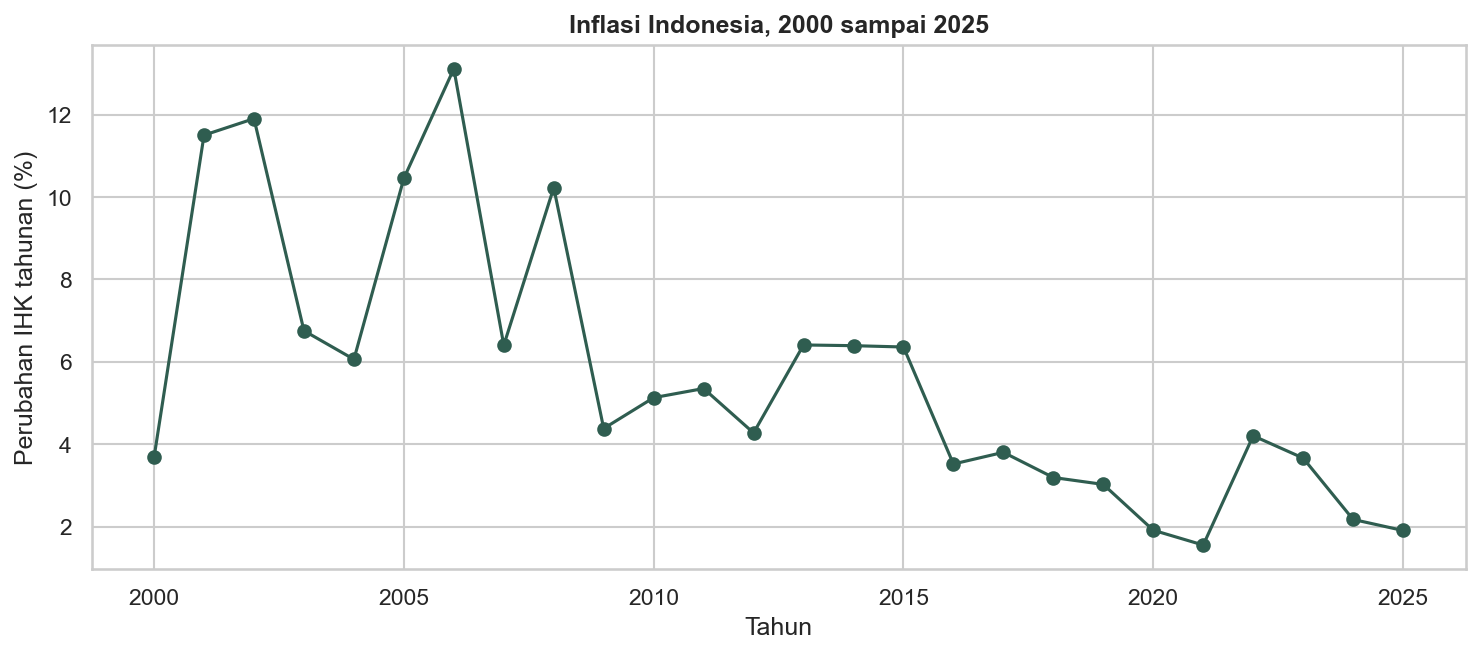

In [16]:
makro_spss.plot(x="tahun", y="Inflasi", marker="o", color="#2F5D50",
                figsize=(10, 4.5), legend=False)
plt.title("Inflasi Indonesia, 2000 sampai 2025")
plt.xlabel("Tahun")
plt.ylabel("Perubahan IHK tahunan (%)")
plt.xticks([2000, 2005, 2010, 2015, 2020, 2025])
plt.tight_layout()
plt.show()

**Cara membaca:** satu titik adalah satu tahun. Nilai yang lebih tinggi
menunjukkan laju kenaikan Indeks Harga Konsumen (IHK) yang lebih besar.
Nilai 5 berarti kenaikan sekitar 5 persen dari tahun sebelumnya. Grafik
memperlihatkan perubahan laju inflasi, bukan level harga. Inflasi tahunan
World Bank ini jangan disamakan langsung dengan inflasi bulanan.

### Histogram: seberapa sering suatu rentang nilai muncul?

Grafik garis menjaga urutan tahun. Histogram mengelompokkan nilai inflasi
ke dalam enam rentang, lalu menghitung banyaknya tahun pada setiap rentang.

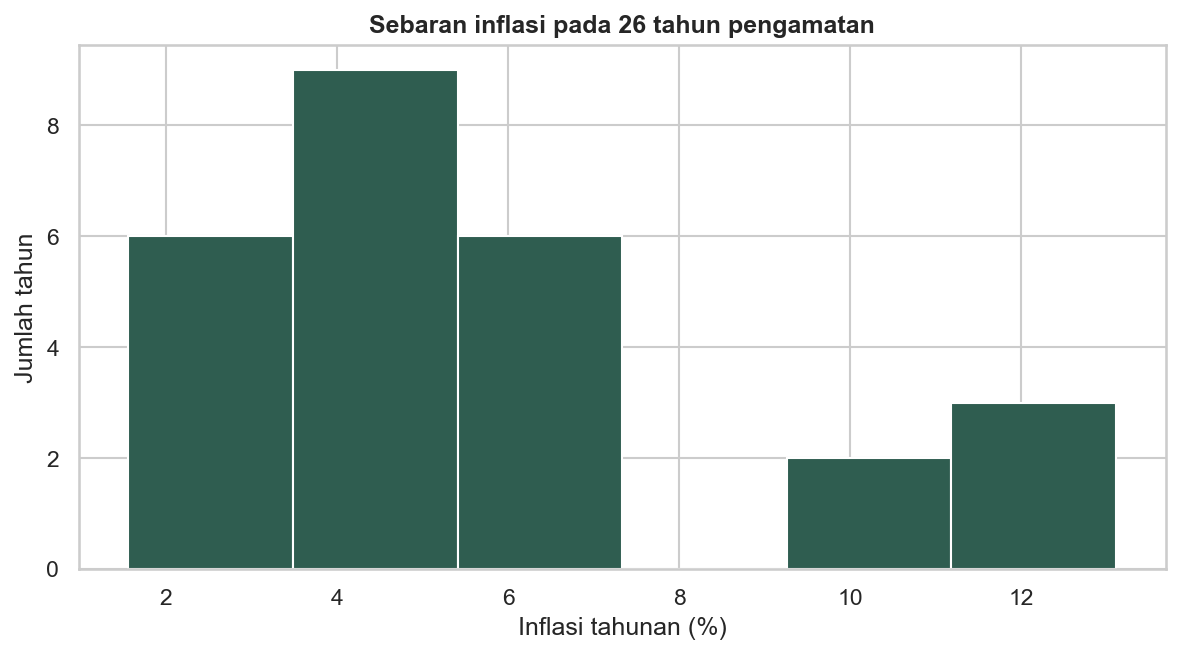

In [17]:
plt.figure(figsize=(8, 4.5))
plt.hist(makro_csv["Inflasi"], bins=6, color="#2F5D50", edgecolor="white")
plt.xlabel("Inflasi tahunan (%)")
plt.ylabel("Jumlah tahun")
plt.title("Sebaran inflasi pada 26 tahun pengamatan")
plt.tight_layout()
plt.show()

**Cara membaca:** tinggi batang menunjukkan jumlah tahun pada rentang
inflasi di bawahnya. Jumlah seluruh batang adalah 26 tahun. Batang yang lebih
tinggi berarti rentang itu lebih sering muncul. Urutan tahun tidak terlihat
pada histogram; gunakan grafik garis untuk melihat kapan nilainya terjadi.

### Diagram pencar: apakah dua indikator bergerak bersama?

Satu titik mewakili satu tahun. Kita meletakkan pengangguran pada sumbu X
dan inflasi pada sumbu Y. Grafik ini hanya memperlihatkan pasangan angka.

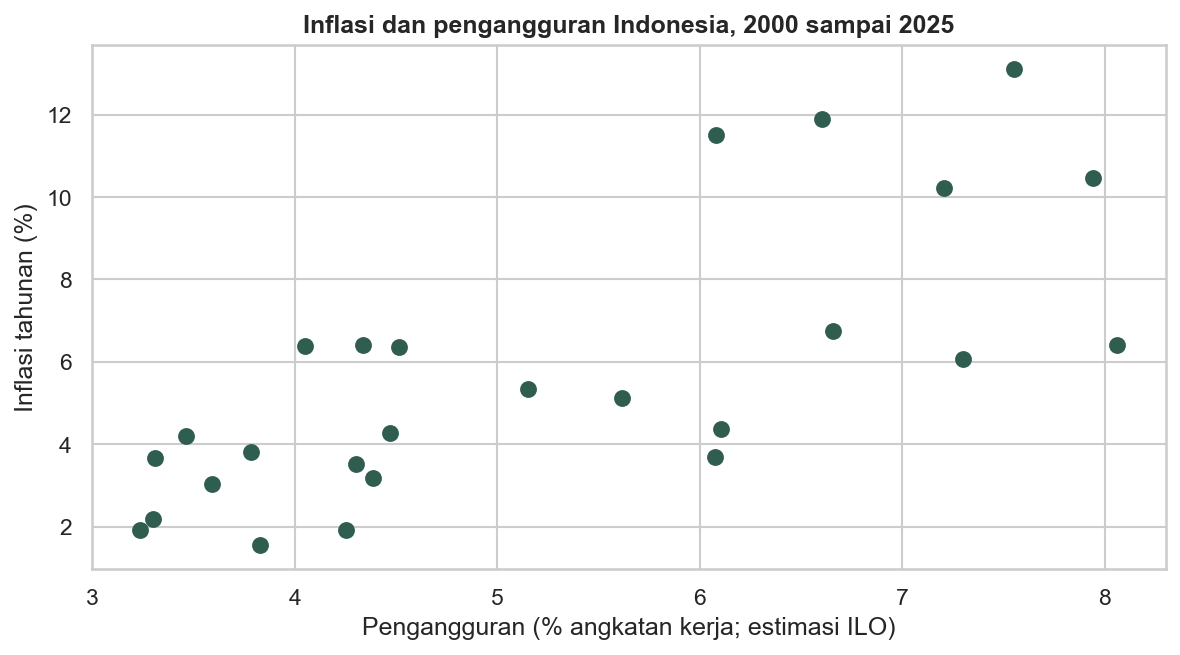

In [18]:
plt.figure(figsize=(8, 4.5))
plt.scatter(makro_csv["Pengangguran"], makro_csv["Inflasi"], color="#2F5D50", s=50)
plt.xlabel("Pengangguran (% angkatan kerja; estimasi ILO)")
plt.ylabel("Inflasi tahunan (%)")
plt.title("Inflasi dan pengangguran Indonesia, 2000 sampai 2025")
plt.tight_layout()
plt.show()

**Cara membaca:** titik di kanan memiliki pengangguran lebih tinggi;
titik di atas memiliki inflasi lebih tinggi. Cari kelompok titik dan
pengamatan yang jauh dari kelompoknya. Hubungan yang terlihat dapat
berkaitan dengan waktu, krisis, atau faktor lain yang belum diperiksa.

## 6. Bandingkan data 34 provinsi pada 2021

Tabel makro membandingkan tahun. Tabel berikut membandingkan provinsi pada
tahun yang sama. Kenali arti kolom sebelum memilih indikator yang digambar.
Kita memakai `Provinsi`, `Kemiskinan`, dan `IPM` untuk eksplorasi awal.

<!-- kamus_variabel:provinsi_2021.csv -->

### Kenali data: Indikator 34 provinsi tahun 2021

**Data:** `data/provinsi_2021.csv`. **Satu baris:** satu provinsi pada tahun 2021 dalam kompilasi sumber.

| Variabel/kolom | Pengertian | Satuan atau kode |
|---|---|---|
| `Provinsi` | Nama provinsi yang diamati. | Nama wilayah |
| `PDRB_Kapita` | Produk Domestik Regional Bruto per penduduk, ukuran output ekonomi per kapita. | Skala sumber; dipakai sebagai ribu rupiah dalam tutorial |
| `IPM` | Indeks Pembangunan Manusia yang merangkum dimensi kesehatan, pendidikan, dan taraf hidup. | Poin indeks, bukan persen |
| `Pengangguran` | Tingkat Pengangguran Terbuka (TPT). | Persen angkatan kerja |
| `Kemiskinan` | Penduduk yang berada di bawah garis kemiskinan. | Persen penduduk |
| `AHH_Laki` | Angka Harapan Hidup laki-laki pada kompilasi sumber. | Tahun |
| `AHH_Perempuan` | Angka Harapan Hidup perempuan pada kompilasi sumber. | Tahun |
| `APS_7_12` | Angka Partisipasi Sekolah penduduk umur 7 sampai 12 tahun. | Persen penduduk kelompok umur tersebut |
| `APS_13_15` | Angka Partisipasi Sekolah penduduk umur 13 sampai 15 tahun. | Persen penduduk kelompok umur tersebut |
| `APS_16_18` | Angka Partisipasi Sekolah penduduk umur 16 sampai 18 tahun. | Persen penduduk kelompok umur tersebut |
| `APS_19_23` | Angka Partisipasi Sekolah penduduk umur 19 sampai 23 tahun. | Persen penduduk kelompok umur tersebut |
| `Perokok` | Persentase perokok pada kompilasi data provinsi. | Persen; cakupan umur mengikuti sumber |

Berkas ini adalah kompilasi indikator, bukan tabel metadata lengkap BPS. Cakupan indikator dan skala PDRB perlu diperiksa pada sumber BPS sebelum dipakai untuk riset; barisnya mengikuti 34 provinsi pada tahun 2021.

Sumber definisi: [rujukan data](https://github.com/sainsdataid/dataset/blob/main/Data%2034%20Provinsi%202021.csv).


In [19]:
provinsi = pd.read_csv(URL_DATA + "provinsi_2021.csv")
provinsi[["Provinsi", "Kemiskinan", "IPM"]].head()

,Provinsi,Kemiskinan,IPM
0,Aceh,15.33,72.18
1,Sumatera Utara,9.01,72.00
2,Sumatera Barat,6.63,72.65
3,Riau,7.12,72.94
4,Jambi,8.09,71.63


### Grafik batang: bandingkan wilayah

`nlargest` memilih provinsi dengan persentase kemiskinan tertinggi.
`sort_values` mengatur urutan agar batang paling tinggi berada di bagian atas.
Tanda `%` menunjukkan persentase penduduk, bukan jumlah orang.

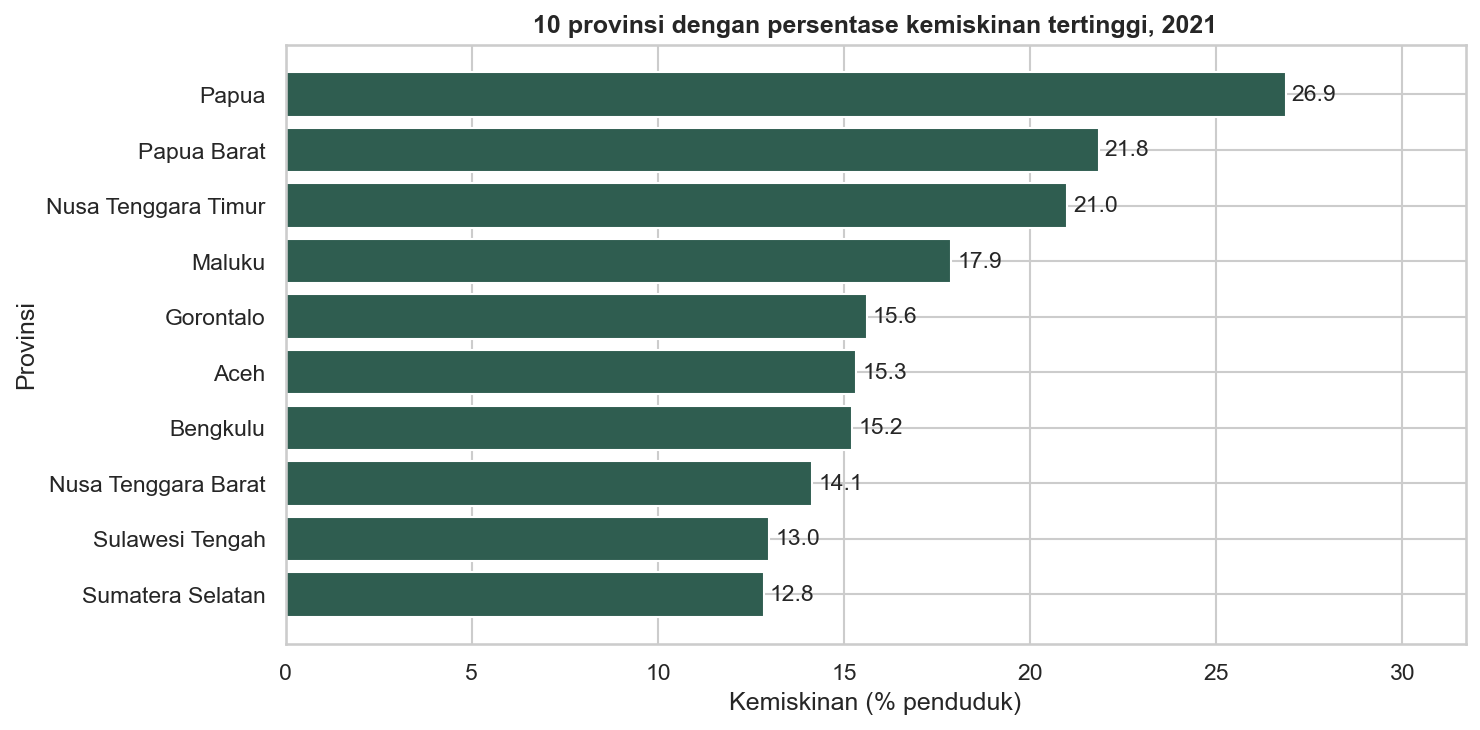

In [20]:
peringkat = provinsi.nlargest(10, "Kemiskinan")
peringkat = peringkat.sort_values("Kemiskinan")
fig, ax = plt.subplots(figsize=(10, 5))
batang = ax.barh(peringkat["Provinsi"], peringkat["Kemiskinan"], color="#2F5D50")
ax.bar_label(batang, fmt="%.1f", padding=3)
ax.set_xlabel("Kemiskinan (% penduduk)")
ax.set_ylabel("Provinsi")
ax.set_title("10 provinsi dengan persentase kemiskinan tertinggi, 2021")
ax.set_xlim(0, peringkat["Kemiskinan"].max() * 1.18)
plt.tight_layout()
plt.show()

**Cara membaca:** satu batang mewakili satu provinsi. Panjang batang dan
angka di ujungnya menunjukkan persentase penduduk miskin. Grafik menampilkan
10 dari 34 provinsi pada berkas tahun 2021. Peringkat persentase ini berbeda
dari peringkat jumlah penduduk miskin; jumlah orang membutuhkan data penduduk.

## Latihan singkat

1. Tampilkan tahun dengan inflasi lebih dari 8 persen.
2. Hitung rata-rata inflasi untuk tahun 2015 dan sesudahnya.
3. Ubah grafik peringkat agar menampilkan lima provinsi dengan IPM tertinggi.
   Sesuaikan judul dan satuan: IPM adalah poin indeks, bukan persen.

Kerjakan dengan menyalin pola perintah yang sudah dijalankan.

In [21]:
# Tulis hasil eksplorasi dan kode latihan Anda di sini.

## Tulis hasil eksplorasi

Tuliskan tiga kalimat: pola yang terlihat, satuan dan periode datanya, serta
satu pertanyaan yang masih perlu diteliti. Hindari menyimpulkan sebab akibat
hanya dari rata-rata, peringkat, atau kedekatan titik pada grafik.

Contoh pertanyaan: mengapa inflasi berubah antar tahun, atau mengapa tingkat
kemiskinan berbeda antarprovinsi? EDA membantu merumuskan pertanyaan tersebut.

## Pendampingan AI

> Saya baru belajar coding. Jelaskan sel pembacaan atau grafik ini satu baris
> setiap kali. Sebutkan arti kolom, satuan, dan cara membaca hasilnya.
> Tetap gunakan pandas dan jangan menambahkan pemodelan pada sesi EDA ini.

Cocokkan penjelasannya dengan tabel dan grafik yang benar-benar muncul.

### Selanjutnya

Sesi 01 memperkenalkan regresi. Bekal dari Sesi 00 adalah kemampuan membaca,
memeriksa, merangkum, serta menggambar data sebelum memasang model.

## Selanjutnya

Kerjakan [Lab 00](https://colab.research.google.com/github/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/02_latihan/00_persiapan_colab.ipynb) untuk mengulang materi ini. Lanjutkan ke [Sesi 01: regresi linear dan prediksi](https://colab.research.google.com/github/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/01_ekonometrika/01_regresi_dasar.ipynb).